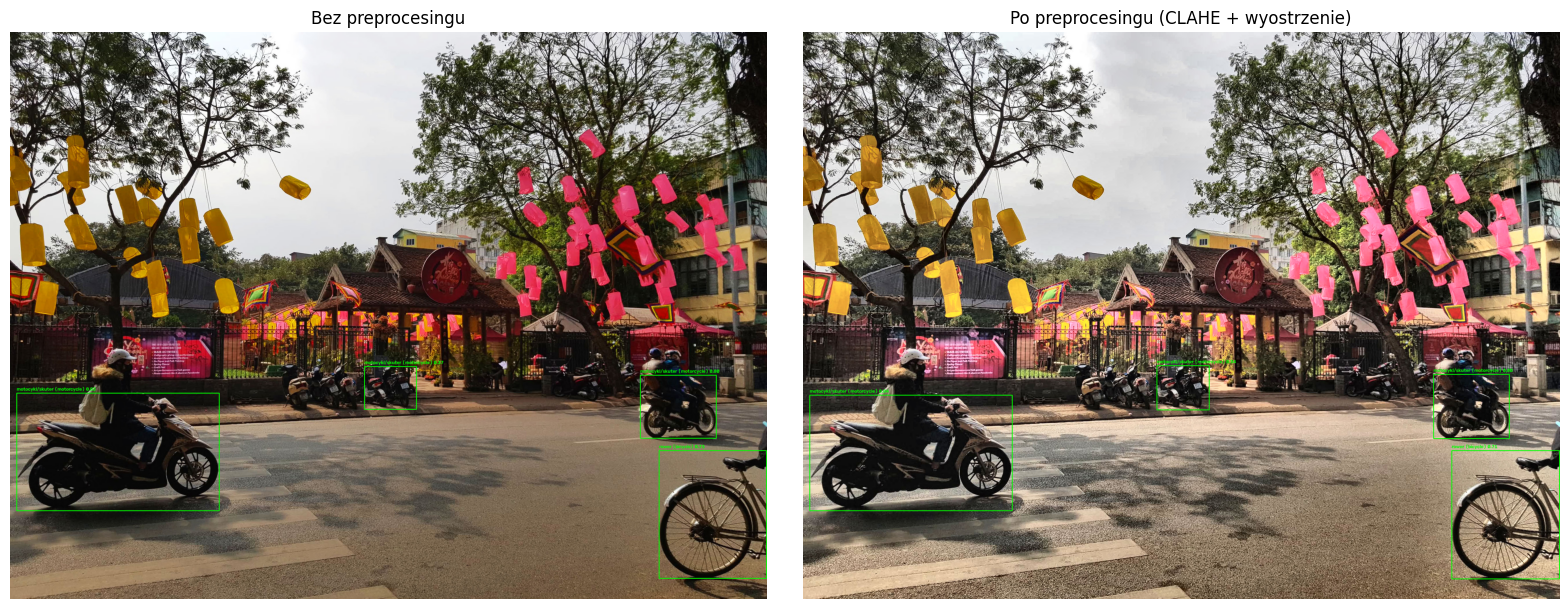

=== PODSUMOWANIE: BEZ PREPROCESINGU ===
- rower (bicycle): 1
- motocykl/skuter (motorcycle): 3

=== PODSUMOWANIE: PO PREPROCESINGU ===
- rower (bicycle): 1
- motocykl/skuter (motorcycle): 3


In [7]:
!pip install -q ultralytics

import urllib.request
from urllib.error import HTTPError, URLError
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

# ==========================================
# 1. Wczytanie zdalnego obrazu z ulicy
# ==========================================
# Podmień na bezpośredni link do wybranego zdjęcia (np. z Wikimedia Commons, bez /thumb/)
image_url = "https://upload.wikimedia.org/wikipedia/commons/9/94/A_day_before_New_Year%27s_%28T%E1%BA%BFt%29_celebration.jpg?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original"

def load_remote_image(url: str):
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
    req = urllib.request.Request(url, headers=headers)
    try:
        with urllib.request.urlopen(req, timeout=20) as response:
            data = np.asarray(bytearray(response.read()), dtype=np.uint8)
            img_bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
            if img_bgr is None:
                raise RuntimeError("Nie udało się zdekodować obrazu.")
            return img_bgr
    except (HTTPError, URLError) as e:
        raise RuntimeError(f"Błąd pobierania obrazu ({e}). Sprawdź adres URL.")

raw_bgr = load_remote_image(image_url)

# ==========================================
# 2. Preprocesing obrazu (CLAHE na kanale jasności + delikatne wyostrzenie)
# ==========================================
def preprocess_for_detection(bgr_img):
    # Konwersja do YCrCb pozwala poprawić kontrast na kanale jasności Y bez psucia kolorów
    ycrcb = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2YCrCb)
    y, cr, cb = cv2.split(ycrcb)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    y_enhanced = clahe.apply(y)

    merged_bgr = cv2.cvtColor(cv2.merge((y_enhanced, cr, cb)), cv2.COLOR_YCrCb2BGR)

    # Lekkie wyostrzenie krawędzi w celu poprawy czytelności konturów
    blurred = cv2.GaussianBlur(merged_bgr, (0, 0), sigmaX=1.0)
    sharpened_bgr = cv2.addWeighted(merged_bgr, 1.2, blurred, -0.2, 0)
    return sharpened_bgr

prep_bgr = preprocess_for_detection(raw_bgr)

# ==========================================
# 3. Detekcja obiektów i zliczanie
# ==========================================
model = YOLO("yolov8n.pt")

# W zbiorze COCO: 1 = 'bicycle' (rower), 3 = 'motorcycle' (motocykl/skuter)
# Uwaga: standardowy model COCO nie ma osobnej klasy dla hulajnóg miejskich.
target_classes = {1: "rower (bicycle)", 3: "motocykl/skuter (motorcycle)"}

def detect_and_count(bgr_img, conf_threshold=0.30):
    res = model(bgr_img, conf=conf_threshold, verbose=False)[0]
    counts = {name: 0 for name in target_classes.values()}
    annotated = bgr_img.copy()

    for box in res.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        if cls_id in target_classes:
            label_name = target_classes[cls_id]
            counts[label_name] += 1

            x1, y1, x2, y2 = map(int, box.xyxy[0])
            cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(
                annotated,
                f"{label_name} {conf:.2f}",
                (x1, max(y1 - 8, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2,
            )

    return annotated, counts

raw_annotated, raw_counts = detect_and_count(raw_bgr, conf_threshold=0.30)
prep_annotated, prep_counts = detect_and_count(prep_bgr, conf_threshold=0.30)

# ==========================================
# 4. Wizualizacja porównania przed i po preprocesingu
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(cv2.cvtColor(raw_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Bez preprocesingu")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(prep_annotated, cv2.COLOR_BGR2RGB))
axes[1].set_title("Po preprocesingu (CLAHE + wyostrzenie)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("=== PODSUMOWANIE: BEZ PREPROCESINGU ===")
for k, v in raw_counts.items():
    print(f"- {k}: {v}")

print("\n=== PODSUMOWANIE: PO PREPROCESINGU ===")
for k, v in prep_counts.items():
    print(f"- {k}: {v}")